# 01. 데이터 탐색 (EDA) — SCENT MATCH · Team 12

이 노트북은 향수 추천 시스템에 쓴 데이터 4종을 탐색하고, 그 결과가 **모델 설계 결정**(0점 제외, 유저 기준 3/4/5, 하이브리드, 정확 매칭)으로 어떻게 이어졌는지 보여준다.

| 데이터 | 역할 |
|---|---|
| Fragrantica (`fra_cleaned.csv`) | 콘텐츠 기반 추천의 향수 특성(노트·어코드) |
| Atrafshan (`atrafshan_data.json`) | 협업 필터링 학습용 유저 평점 |
| Basenotes (`perfumes.json`, `reviews.json` 등) | 외부 테스트용 유저 평점 |
| Parfumo (`parfumo_data_clean.csv`) | 보조 교차 확인 |

**실행 전 준비:** 원본 데이터는 Git에 올리지 않는다(`.gitignore`). 프로젝트 루트의 `Term-project-datasets/` 폴더에 데이터 zip을 풀어 둔 뒤 실행한다.

**주의:** 이 노트북은 탐색만 하며 모델 학습, 검증/테스트 평가, `outputs/`의 동결 자산에는 손대지 않는다.

In [1]:
# 라이브러리 불러오기 (수업에서 사용한 numpy, pandas, matplotlib만 사용)
import json
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 노트북을 notebooks/ 안에서 열든 프로젝트 루트에서 열든 같은 경로를 쓰도록 맞춘다
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
DATA = ROOT / 'Term-project-datasets'
assert DATA.exists(), f'데이터 폴더가 없습니다: {DATA}'

# 그래프 기본 설정: 발표 자료에 바로 쓸 수 있도록 영어 라벨 + 큰 글씨
plt.rcParams.update({'figure.dpi': 110, 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
COLOR, ACCENT = '#2F5496', '#C0504D'

## 1. 데이터 불러오기와 규모 확인

In [2]:
# Fragrantica: 구분자가 ';'이고 Windows 인코딩(cp1252)으로 저장된 CSV
fra = pd.read_csv(DATA / 'fra_cleaned.csv', sep=';', encoding='cp1252')

# Atrafshan: 댓글 1건 = 레코드 1개인 JSON (페르시아어 키 포함)
with open(DATA / 'atrafshan_data.json', encoding='utf-8-sig') as f:
    atr_raw = json.load(f)

# Basenotes: Django fixture 형식(pk, model, fields)의 JSON 여러 개
def load_fixture(name):
    """Basenotes JSON을 읽어 fields를 펼친 DataFrame으로 변환한다. pk는 각 행의 ID."""
    with open(DATA / f'{name}.json', encoding='utf-8-sig') as f:
        rows = json.load(f)
    return pd.DataFrame([{'pk': r['pk'], **r['fields']} for r in rows])

bn_perfumes = load_fixture('perfumes')
bn_reviews = load_fixture('reviews')
bn_brand = load_fixture('brand')

# Parfumo: 보조 데이터
parfumo = pd.read_csv(DATA / 'parfumo_data_clean.csv')

pd.DataFrame({
    'dataset': ['Fragrantica', 'Atrafshan (records)', 'Basenotes perfumes', 'Basenotes reviews', 'Parfumo'],
    'rows': [len(fra), len(atr_raw), len(bn_perfumes), len(bn_reviews), len(parfumo)],
})

,dataset,rows
0,Fragrantica,24063
1,Atrafshan (records),36434
2,Basenotes perfumes,39699
3,Basenotes reviews,6288
4,Parfumo,59325


## 2. Fragrantica — 향수 특성 데이터

콘텐츠 기반 추천은 향수를 노트·어코드 단어 묶음으로 표현한다. 먼저 결측치와 자주 나오는 특성을 본다.

In [3]:
# 컬럼별 결측치 개수: 노트·어코드1은 거의 비어 있지 않아 콘텐츠 특성으로 쓰기 좋다
fra.isna().sum().to_frame('missing').T

,url,Perfume,Brand,Country,Gender,Rating Value,Rating Count,Year,Top,Middle,Base,Perfumer1,Perfumer2,mainaccord1,mainaccord2,mainaccord3,mainaccord4,mainaccord5
missing,0,0,0,0,0,0,0,2037,0,0,0,0,22727,0,13,114,388,981


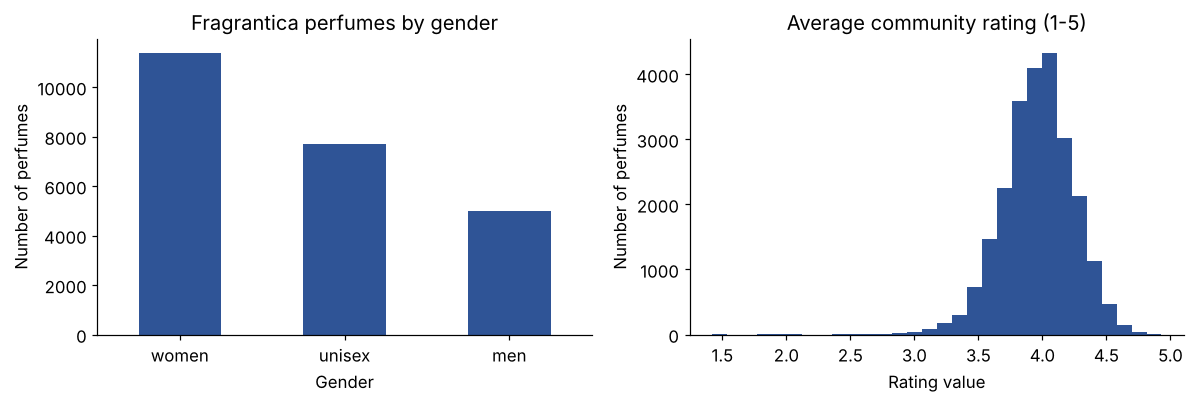

In [4]:
# 성별 구분과 평균 평점 분포
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
fra['Gender'].value_counts().plot.bar(ax=axes[0], color=COLOR)
axes[0].set_title('Fragrantica perfumes by gender')
axes[0].set_ylabel('Number of perfumes')
axes[0].tick_params(axis='x', rotation=0)

# 'Rating Value'는 '1,42'처럼 소수점이 쉼표라 숫자로 바꿔야 한다
rating_value = fra['Rating Value'].astype(str).str.replace(',', '.').astype(float)
axes[1].hist(rating_value, bins=30, color=COLOR)
axes[1].set_title('Average community rating (1-5)')
axes[1].set_xlabel('Rating value')
axes[1].set_ylabel('Number of perfumes')
plt.tight_layout()
plt.show()

서로 다른 노트 1,671개, 서로 다른 어코드 84개


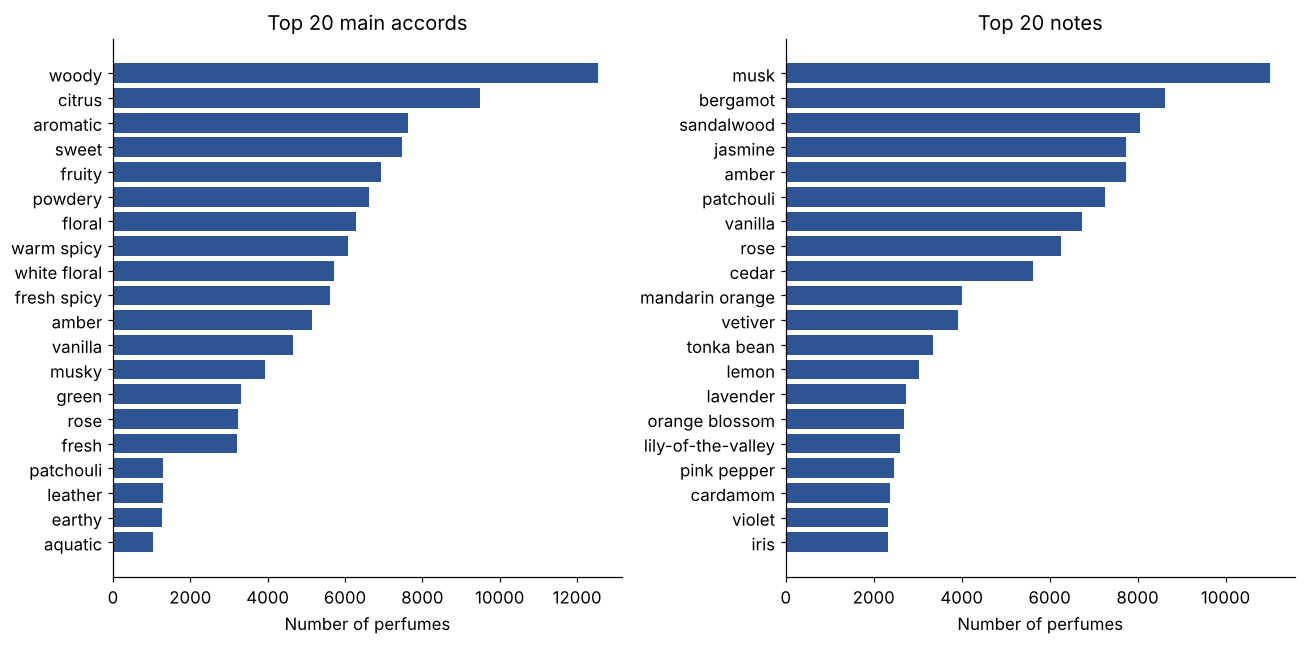

In [5]:
def split_list(series):
    """쉼표로 이어진 문자열 컬럼을 하나의 긴 리스트로 펼친다. 'unknown'과 빈 값은 버린다."""
    items = []
    for value in series.dropna():
        for token in str(value).split(','):
            token = token.strip().lower()
            if token and token != 'unknown':
                items.append(token)
    return items

# 노트: 탑·미들·베이스를 모두 합쳐 센다
note_counts = Counter(split_list(fra['Top']) + split_list(fra['Middle']) + split_list(fra['Base']))
# 어코드: mainaccord1~5를 모두 합쳐 센다
accord_counts = Counter(split_list(pd.concat([fra[f'mainaccord{i}'] for i in range(1, 6)])))

print(f'서로 다른 노트 {len(note_counts):,}개, 서로 다른 어코드 {len(accord_counts):,}개')

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, counts, title in [(axes[0], accord_counts, 'Top 20 main accords'), (axes[1], note_counts, 'Top 20 notes')]:
    top = counts.most_common(20)[::-1]          # 가로 막대는 아래부터 그려지므로 뒤집는다
    ax.barh([k for k, _ in top], [v for _, v in top], color=COLOR)
    ax.set_title(title)
    ax.set_xlabel('Number of perfumes')
plt.tight_layout()
plt.show()

**관찰:** 머스크·베르가못·우디처럼 대부분의 향수에 들어 있는 특성이 많다. 흔한 단어가 유사도를 지배하지 않도록 **TF-IDF**로 흔한 특성의 가중치를 낮추는 근거가 된다.

## 3. Atrafshan — 유저 평점 데이터

각 레코드에는 유저가 남긴 4가지 점수(향기 `رایحه`, 지속력 `ماندگاری`, 확산력 `پخش بو`, 병 디자인 `طراحی شیشه`)가 있다. 추천에는 **향기 점수**를 쓴다.

In [6]:
# 필요한 값만 꺼내서 표로 만든다. 점수가 없는 레코드(댓글만 있는 경우)는 NaN이 된다
KEYS = {'scent': 'رایحه', 'longevity': 'ماندگاری', 'sillage': 'پخش بو', 'design': 'طراحی شیشه'}
records = []
for r in atr_raw:
    votes = (r.get('user_vote_on_perfume') or {}).get('votes') or {}
    records.append({'user': r['user_id'], 'perfume': r['perfume_id'], 'brand': r['perfume_brand'],
                    'name': r['perfume_name'], **{k: votes.get(v) for k, v in KEYS.items()}})
atr = pd.DataFrame(records)
for k in KEYS:
    atr[k] = pd.to_numeric(atr[k], errors='coerce')

rated = atr.dropna(subset=['scent'])
print(f'전체 레코드 {len(atr):,}개 중 향기 점수가 있는 레코드 {len(rated):,}개')

전체 레코드 36,434개 중 향기 점수가 있는 레코드 6,882개


0점: 1,309개 (19.0%)


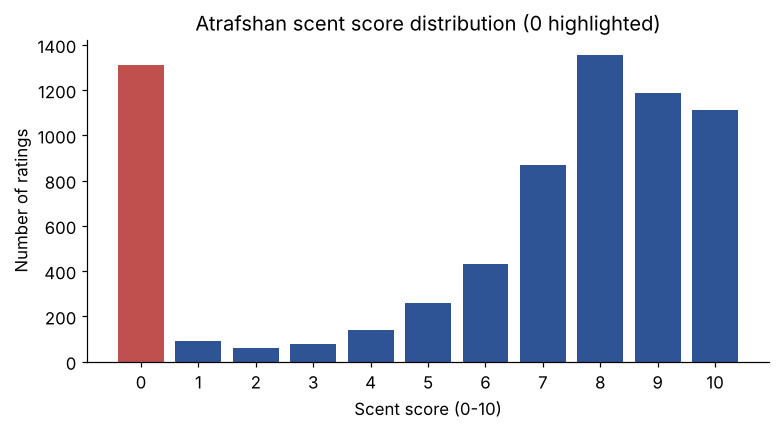

In [7]:
# 향기 점수 분포: 0점이 비정상적으로 많다
dist = rated['scent'].value_counts().sort_index()
plt.figure(figsize=(8, 3.8))
plt.bar(dist.index, dist.values, color=[ACCENT if x == 0 else COLOR for x in dist.index])
plt.title('Atrafshan scent score distribution (0 highlighted)')
plt.xlabel('Scent score (0-10)')
plt.ylabel('Number of ratings')
plt.xticks(range(11))
plt.show()
print(f'0점: {int(dist.get(0, 0)):,}개 ({dist.get(0, 0) / dist.sum():.1%})')

향기 0점인 행 중 지속력 점수가 5 이상인 비율: 96.2%
향기 0점인 행 중 병 디자인도 0점인 비율: 99.5%


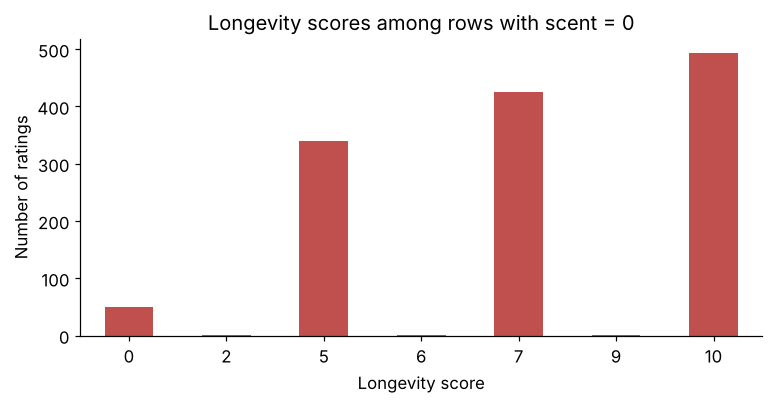

In [8]:
# 0점이 '정말 싫다'인지 '평가 안 함'인지 확인: 향기 0점인 행의 지속력 점수를 본다
zero = rated[rated['scent'] == 0]
print(f"향기 0점인 행 중 지속력 점수가 5 이상인 비율: {(zero['longevity'] >= 5).mean():.1%}")
print(f"향기 0점인 행 중 병 디자인도 0점인 비율: {(zero['design'] == 0).mean():.1%}")

plt.figure(figsize=(8, 3.5))
zero['longevity'].dropna().astype(int).value_counts().sort_index().plot.bar(color=ACCENT)
plt.title('Longevity scores among rows with scent = 0')
plt.xlabel('Longevity score')
plt.ylabel('Number of ratings')
plt.xticks(rotation=0)
plt.show()

**관찰:** 향기 0점인 행의 대부분은 지속력을 5점 이상으로 주었고, 병 디자인도 거의 다 0점이다. 향이 최악이라면서 오래 간다고 높게 평가하는 것은 부자연스럽고, 디자인 0점이 함께 나타나는 것은 그 항목을 건너뛴 패턴에 가깝다. 따라서 0은 **"평가하지 않음"일 가능성이 높다**. 그래서 프로젝트는 **0점 제외를 주 분석**으로, 0점 포함을 민감도 분석으로 진행했다(의미가 확정된 것은 아님).

유효 평점 5,573개 | 유저 1,748명 | 향수 1,050개
평점 행렬 밀도: 0.30%  (나머지 99.70%는 빈칸)
유저당 평점 수 중앙값: 1개, 1개만 남긴 유저: 54%


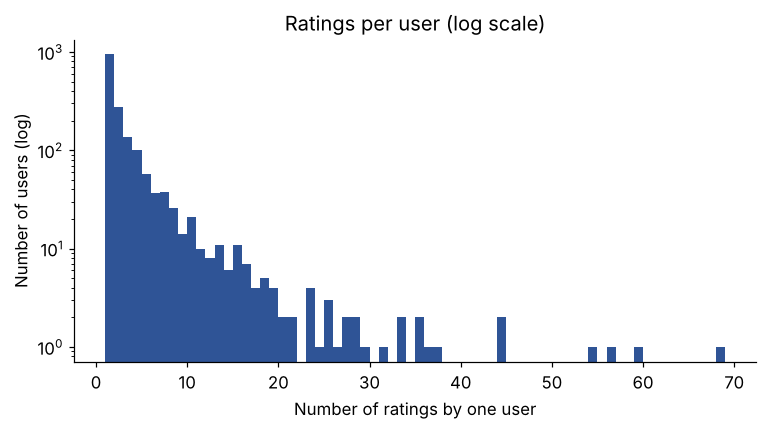

In [9]:
# 0점을 뺀 유효 평점으로 희소성을 확인한다
valid = rated[rated['scent'] > 0].drop_duplicates(['user', 'perfume'])
n_users, n_items = valid['user'].nunique(), valid['perfume'].nunique()
density = len(valid) / (n_users * n_items)
per_user = valid.groupby('user').size()

print(f'유효 평점 {len(valid):,}개 | 유저 {n_users:,}명 | 향수 {n_items:,}개')
print(f'평점 행렬 밀도: {density:.2%}  (나머지 {1 - density:.2%}는 빈칸)')
print(f'유저당 평점 수 중앙값: {per_user.median():.0f}개, 1개만 남긴 유저: {(per_user == 1).mean():.0%}')

plt.figure(figsize=(8, 3.8))
plt.hist(per_user, bins=range(1, per_user.max() + 2), color=COLOR)
plt.yscale('log')
plt.title('Ratings per user (log scale)')
plt.xlabel('Number of ratings by one user')
plt.ylabel('Number of users (log)')
plt.show()

In [10]:
# 학습 유저 기준(평점 3/4/5개 이상)별로 남는 데이터 — 제안서에서 비교하기로 한 세 가지 실험
rows = []
for k in (3, 4, 5):
    keep = per_user[per_user >= k].index
    rows.append({'min ratings per user': k, 'users': len(keep),
                 'ratings': int(valid['user'].isin(keep).sum())})
pd.DataFrame(rows)

,min ratings per user,users,ratings
0,3,528,4080
1,4,391,3669
2,5,291,3269


**관찰:** 밀도가 1%도 안 되고 대부분의 유저가 평점을 1개만 남겼다. 평점만 쓰는 협업 필터링(MF)으로는 정보가 부족하므로 **콘텐츠 기반과 결합한 하이브리드**가 필요하다. 또한 평점이 너무 적은 유저는 학습에서 빼야 하므로 3/4/5개 기준을 검증셋으로 비교했다(최종 선택: 3개).

> 참고: 위 숫자는 Fragrantica와 매칭하기 **전** Atrafshan 전체 기준이다. 실제 학습은 매칭된 향수만 사용하므로 수치가 더 작다.

## 4. Basenotes — 외부 테스트 데이터

리뷰 6,288개 | 유저 877명 | 평가된 향수 2,694개
유저당 리뷰 수 중앙값: 1개


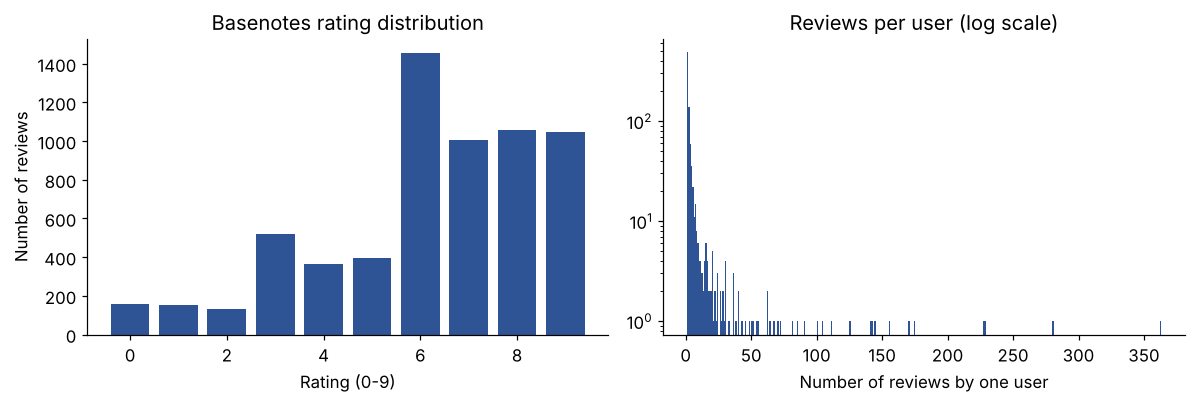

In [11]:
bn_rate = bn_reviews['rate'].value_counts().sort_index()
bn_per_user = bn_reviews.groupby('user').size()
print(f"리뷰 {len(bn_reviews):,}개 | 유저 {bn_reviews['user'].nunique():,}명 | 평가된 향수 {bn_reviews['perfume'].nunique():,}개")
print(f'유저당 리뷰 수 중앙값: {bn_per_user.median():.0f}개')

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(bn_rate.index, bn_rate.values, color=COLOR)
axes[0].set_title('Basenotes rating distribution')
axes[0].set_xlabel('Rating (0-9)')
axes[0].set_ylabel('Number of reviews')
axes[1].hist(bn_per_user, bins=range(1, bn_per_user.max() + 2), color=COLOR)
axes[1].set_yscale('log')
axes[1].set_title('Reviews per user (log scale)')
axes[1].set_xlabel('Number of reviews by one user')
plt.tight_layout()
plt.show()

**관찰:** Atrafshan(1-10점)과 Basenotes(0-9점)는 점수 척도가 다르다. 그래서 외부 테스트에서는 점수를 직접 비교하는 MAE/RMSE 대신 **순위 지표**(Precision/Recall/NDCG@10)를 사용했다.

## 5. 데이터셋 간 향수 매칭

세 사이트는 향수 ID가 서로 다르므로 **브랜드 + 이름**으로 연결해야 한다. 프로젝트의 실제 전처리 함수(`src/perfume/data.py`)를 그대로 불러와서, 모델과 같은 기준(정규화 후 정확히 하나와 일치할 때만 인정)으로 매칭률을 센다.

In [12]:
# 팀의 전처리 모듈을 불러온다 (모델과 동일한 매칭 규칙 사용)
sys.path.insert(0, str(ROOT / 'src'))
from perfume.data import fragrantica, matcher, match

catalog, _ = fragrantica(DATA / 'fra_cleaned.csv')
index = matcher(catalog)

# Atrafshan: 평점이 있는 향수만 대상으로, audit.py와 똑같이 브랜드·이름을 그대로 넣어 매칭
atr_items = valid.drop_duplicates('perfume')
atr_status = Counter(match(index, b, n)[1] for b, n in zip(atr_items['brand'], atr_items['name']))

# Basenotes: 리뷰가 있는 향수만 대상으로 매칭 (브랜드는 숫자 코드라 이름으로 복원)
brand_name = dict(zip(bn_brand['pk'], bn_brand['name']))
bn_items = bn_perfumes[bn_perfumes['pk'].isin(bn_reviews['perfume'])]
bn_status = Counter(match(index, brand_name.get(b, ''), n)[1] for b, n in zip(bn_items['brand'], bn_items['name']))

match_table = pd.DataFrame([atr_status, bn_status], index=['Atrafshan (rated)', 'Basenotes (reviewed)']).fillna(0).astype(int)
match_table['match rate'] = (match_table['accepted'] / match_table.sum(axis=1)).map('{:.1%}'.format)
match_table

,rejected,accepted,ambiguous,match rate
Atrafshan (rated),407,641,2,61.0%
Basenotes (reviewed),1856,836,2,31.0%


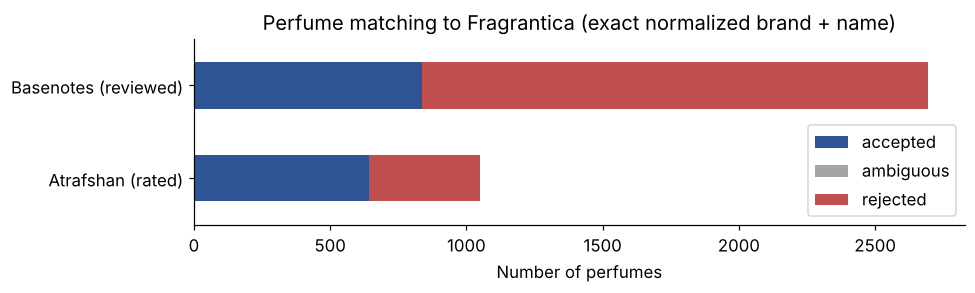

In [13]:
# 매칭 결과 막대그래프 (accepted = 연결 성공, ambiguous = 후보가 여러 개라 제외, rejected = 후보 없음)
plot_table = match_table.drop(columns='match rate')
plot_table = plot_table[[c for c in ['accepted', 'ambiguous', 'rejected'] if c in plot_table]]
plot_table.plot.barh(stacked=True, figsize=(9, 2.8), color=[COLOR, '#A5A5A5', ACCENT])
plt.title('Perfume matching to Fragrantica (exact normalized brand + name)')
plt.xlabel('Number of perfumes')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

**관찰:** 정확 매칭만 인정하면 상당수 향수가 연결되지 않는다. 대신 EDT/EDP처럼 **다른 향수가 잘못 합쳐지는 일은 막을 수 있다**. 이 때문에 MF가 학습할 수 있는 향수, 즉 추천 후보가 479개로 제한되었다. 이 부분은 프로젝트의 한계이자, 다시 한다면 개선할 점이다(예: 수동 검토를 거친 유사 문자열 매칭).

## 6. 요약 — EDA가 모델 설계로 이어진 과정

| EDA에서 발견한 것 | 모델 설계 결정 |
|---|---|
| 흔한 노트·어코드가 많다 | TF-IDF로 흔한 특성의 가중치를 낮춤 |
| 향기 0점인데 지속력은 높은 행이 많다 | 0점 제외를 주 분석, 포함을 민감도 분석 |
| 평점 행렬 밀도가 1% 미만이고, 유저 대부분이 평점 1개 | 콘텐츠 + MF 하이브리드, 유저 기준 3/4/5 비교 |
| 두 사이트의 점수 척도가 다르다 | 외부 테스트는 순위 지표로 평가 |
| 정확 매칭률이 제한적이다 | 오매칭을 막기 위해 정확 매칭 유지, 후보 479개는 한계로 보고 |